# Feed-forward 3D reconstruction with VGGT

**What this notebook does.** It feeds 25 *unposed* photos of a table-top scene to
**VGGT-1B** (Visual Geometry Grounded Transformer, CVPR 2025) and gets back, in a single
forward pass of a few seconds, every camera's pose and intrinsics, a depth map and a
confidence map per view, and a dense point map. These are the outputs a classical
Structure-from-Motion (SfM) pipeline such as COLMAP builds up from feature matching,
RANSAC and bundle adjustment. The 1.26 B-parameter model fits on an 8 GB laptop GPU because
of a mixed-precision loading recipe.

**What you'll learn**
- what a feed-forward reconstructor predicts and in which coordinate conventions
  (OpenCV camera-from-world extrinsics, intrinsics decoded from a field of view);
- how alternating frame-wise / global attention turns a set of images into one consistent
  3D scene, and what that costs in tokens;
- how to fit a 5 GB fp32 checkpoint into 8 GB of VRAM (bf16 backbone, fp32 heads);
- the two routes to 3D points (depth + camera unprojection vs. the direct point-map head)
  and how to use the predicted confidence to filter them;
- how to export a coloured point cloud to `.ply` and sanity-check the cameras against COLMAP.

**Prerequisites:** the pinhole camera model and SE(3) poses (project 07), epipolar
geometry and SfM with COLMAP (project 09). Data and weights come from
`make data-10_feedforward_3d`; the COLMAP reference comes from
`python projects/10_feedforward_3d/scripts/run_colmap.py`.

## Setup
Imports, seeding and the device summary. The plotting style is shared by the whole repository.

In [1]:
# --- Setup: imports, device, repository paths, plotting style ---
# The project helpers live in projects/10_feedforward_3d/scripts/ff3d.py (shared with the
# benchmark script and the solutions), so every number below comes from the same code.
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cvlab import viz
from cvlab.device import setup
from cvlab.io import outputs_dir, project_dir

PROJECT = "10_feedforward_3d"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import ff3d  # noqa: E402

device = setup(seed=0)
viz.set_style()
pd.set_option("display.precision", 3)
print("results dir:", ff3d.rel(ff3d.results_path()))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
results dir: projects/10_feedforward_3d/results


## 1. The input: 25 unposed photos
The *kitchen* scene ships with the VGGT repository (it matches the *kitchen* scene of the
Mip-NeRF 360 dataset): a hand-held camera circles a LEGO bulldozer on a table. Nothing else is
given, not even the focal length. Classical SfM would now detect and match features in all
$\binom{25}{2} = 300$ image pairs; VGGT instead looks at all images jointly.

Kitchen (25 views): 25 images from data/10_feedforward_3d/kitchen/images
COLMAP registered 24/25 images (missing: ['01.png'])


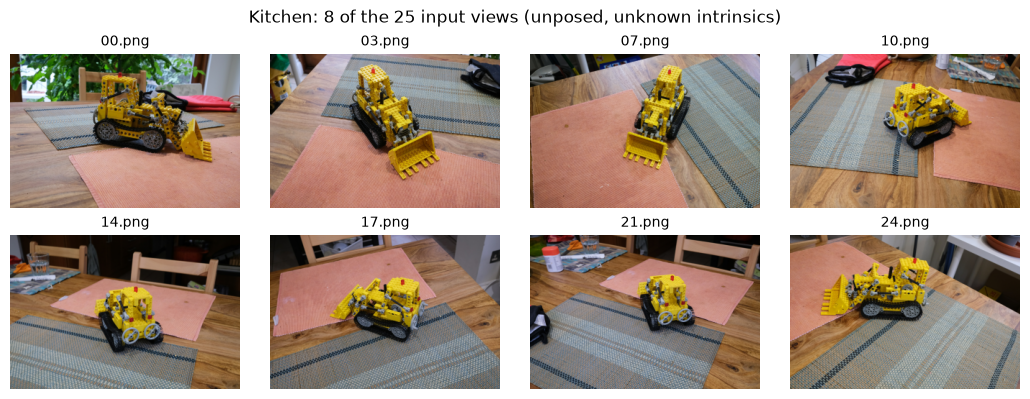

In [2]:
# --- Load the scene and look at a few views ---
# load_scene() returns the image paths plus the reference cameras (here: the COLMAP model
# computed by run_colmap.py on the same 25 images; NaN poses = not registered by COLMAP).
from cvlab.io import read_image

scene = ff3d.load_scene("kitchen")
print(f"{scene.label}: {len(scene)} images from {ff3d.rel(scene.image_paths[0].parent)}")
print(f"COLMAP registered {scene.has_ref.sum()}/{len(scene)} images "
      f"(missing: {[n for n, ok in zip(scene.names, scene.has_ref) if not ok]})")
show = ff3d.evenly_spaced(len(scene), 8)
fig = viz.show_images([read_image(scene.image_paths[i], max_side=320) for i in show],
                      titles=[scene.names[i] for i in show], ncols=4, size=2.6,
                      suptitle="Kitchen: 8 of the 25 input views (unposed, unknown intrinsics)")
plt.show()

## 2. How VGGT works (in one paragraph and a few equations)
Each image is resized to 518 px wide and cut into $14\times14$ patches, embedded by a
DINOv2 ViT-L encoder. Every frame gets one **camera token** and four **register tokens** in
front of its $P = \tfrac{H}{14}\cdot\tfrac{W}{14}$ patch tokens. The trunk then alternates
24 times between

* **frame attention**: tokens attend only within their own image (cost $\mathcal{O}(N P^2)$), and
* **global attention**: all $N(P+5)$ tokens of all images attend to each other
  (cost $\mathcal{O}(N^2 P^2)$). This is where cross-view correspondence and consistency are
  learned, with no explicit feature matching.

Three heads read the resulting tokens:

| head | output | convention |
|---|---|---|
| camera head (on the camera tokens) | $g_i = [\mathbf t_i,\ \mathbf q_i,\ \text{fov}^h_i,\ \text{fov}^w_i] \in \mathbb R^9$ | $T_{cw} = [R(\mathbf q)\,|\,\mathbf t]$, OpenCV (x right, y down, z forward), **camera-from-world** |
| depth head (DPT) | depth $z_i(u,v)$ + confidence $c_i(u,v)$ | distance along the optical axis |
| point head (DPT) | point map $X_i(u,v) \in \mathbb R^3$ + confidence | world frame |

The world frame is the **first camera** ($T_{cw,0} = I$) and the scale is normalised during
training (unit mean distance of the points to the origin), so units are arbitrary.
Intrinsics come from the predicted field of view with the principal point at the image centre:

$$f_x = \frac{W/2}{\tan(\text{fov}^w/2)}, \qquad f_y = \frac{H/2}{\tan(\text{fov}^h/2)}, \qquad c_x = \frac W2,\ c_y = \frac H2 .$$

## 3. Fitting a 1.26 B-parameter model into 8 GB
The checkpoint stores 1.26 B fp32 parameters, which is 5.0 GB before any activations. The
official recipe keeps fp32 weights and runs the backbone under bf16 **autocast**: every matmul
already happens in bf16, while the heads run with autocast disabled. We get the same numerics
for about half the memory by **storing** the 0.91 B-parameter aggregator in bf16 (autocast
would cast its weights to bf16 anyway) and keeping the camera, depth and point heads (0.28 B
parameters together) in fp32. The aggregator tokens are upcast to fp32 before the heads. The
tracking head (66 M parameters) is not used and is dropped.

The model is loaded on the CPU first (about 5 GB of system RAM), cast, and only then moved to
the GPU, so the fp32 copy never touches VRAM.

In [3]:
# --- Load VGGT-1B with the mixed-precision recipe (bf16 aggregator, fp32 heads) ---
# VGGTRunner (scripts/ff3d.py) loads facebook/VGGT-1B from the Hugging Face cache on the CPU,
# drops the unused tracking head, casts the aggregator to bf16 and moves the model to the GPU.
import time

t0 = time.perf_counter()
runner = ff3d.VGGTRunner(precision="mixed")
load_s = time.perf_counter() - t0
rows = []
for name, mod in runner.model.named_children():
    if mod is None:
        continue
    n = sum(p.numel() for p in mod.parameters())
    dtype = next(mod.parameters()).dtype
    rows.append({"module": name, "params (M)": n / 1e6, "dtype": str(dtype).replace("torch.", ""),
                 "weights (MiB)": n * (2 if dtype.itemsize == 2 else 4) / 2**20})
modules = pd.DataFrame(rows)
print(f"loaded in {load_s:.1f} s | {runner.n_params / 1e9:.2f} B parameters on the GPU | "
      f"weights occupy {runner.weights_vram_mb:.0f} MiB of VRAM (fp32 would be "
      f"{runner.n_params * 4 / 2**20:.0f} MiB)")
modules

loaded in 14.8 s | 1.19 B parameters on the GPU | weights occupy 2808 MiB of VRAM (fp32 would be 4542 MiB)


,module,params (M),dtype,weights (MiB)
0,aggregator,909.112,bfloat16,1733.994
1,camera_head,216.175,float32,824.641
2,point_head,32.655,float32,124.568
3,depth_head,32.655,float32,124.567


## 4. Pre-processing and the token budget
VGGT's `crop` mode resizes every image to 518 px wide and rounds the height to a multiple of
the 14 px patch size (images taller than 518 px would be centre-cropped). The global attention
layers see all tokens of all frames at once, which is the quantity that drives runtime.

In [4]:
# --- Pre-process the 25 images and count tokens ---
# images: (N, 3, H, W) float in [0, 1]; H and W are multiples of 14 (the ViT patch size).
images = runner.preprocess(scene.image_paths)
N, _, H, W = images.shape
P = (H // 14) * (W // 14)  # patch tokens per frame
print(f"input {read_image(scene.image_paths[0]).shape[1::-1]} px -> network {W}x{H} px")
print(f"tokens per frame: {P} patches + 1 camera + 4 register = {P + 5}")
print(f"global attention over N*(P+5) = {N * (P + 5):,} tokens "
      f"-> {(N * (P + 5)) ** 2 / 1e9:.1f} G query-key pairs per layer")

input (779, 520) px -> network 518x350 px
tokens per frame: 925 patches + 1 camera + 4 register = 930
global attention over N*(P+5) = 23,250 tokens -> 0.5 G query-key pairs per layer


## 5. One forward pass
`VGGTRunner.predict` runs the aggregator under bf16 autocast, upcasts the cached tokens one
layer at a time, then runs the camera, depth and point heads in fp32. Runtime is measured
around the network only (with `torch.cuda.synchronize`), and the peak VRAM includes the weights.

In [5]:
# --- Run VGGT on all 25 views ---
# A 2-frame warm-up first, so the timed run excludes CUDA/cuDNN initialisation.
_ = runner.predict(scene.image_paths[:2])
rec = runner.predict(scene.image_paths)
print(f"forward pass: {rec.runtime_s:.2f} s for {len(rec)} views "
      f"(incl. image loading + copy to host: {rec.total_s:.2f} s)")
print(f"peak VRAM: {rec.peak_vram_mb:.0f} MiB (of which weights {rec.weights_vram_mb:.0f} MiB)")
print("T_cw:", rec.T_cw.shape, "| K:", rec.K.shape, "| depth:", rec.depth.shape,
      "| conf:", rec.conf.shape, "| point map:", rec.world_points.shape)

forward pass: 6.67 s for 25 views (incl. image loading + copy to host: 7.28 s)
peak VRAM: 5276 MiB (of which weights 2808 MiB)
T_cw: (25, 4, 4) | K: (25, 3, 3) | depth: (25, 350, 518) | conf: (25, 350, 518) | point map: (25, 350, 518, 3)


## 6. Cameras
The extrinsics are camera-from-world matrices, so camera 0 must be the identity and the camera
centre of view $i$ is $C_i = -R_i^\top \mathbf t_i$. The predicted focal length can be compared
with the one COLMAP self-calibrated through bundle adjustment, after rescaling both to the same
image width: the horizontal field of view $\text{fov}_x = 2\arctan\!\big(\tfrac{W}{2 f_x}\big)$
does not depend on the resolution.

In [6]:
# --- Inspect the predicted cameras ---
# The first camera defines the world frame, so its extrinsic should be (numerically) identity.
np.set_printoptions(precision=3, suppress=True)
print("T_cw[0] =\n", rec.T_cw[0])
C = ff3d.camera_centers(rec.T_cw)  # (N, 3) camera centres in VGGT's world frame
print(f"camera centres span {ff3d.trajectory_extent(C):.2f} scene units (VGGT normalises scale)")
fov_vggt = np.array([ff3d.fov_deg(K, rec.proc_hw[1]) for K in rec.K])
ok = scene.has_ref
fov_colmap = ff3d.fov_deg(scene.ref_K[ok][0], scene.ref_size[0])  # one shared COLMAP camera
print(f"horizontal FoV: VGGT {fov_vggt.mean():.2f} +- {fov_vggt.std():.2f} deg (per-view), "
      f"COLMAP {fov_colmap:.2f} deg (shared camera, bundle-adjusted)")

T_cw[0] =
 [[ 1.  0.  0. -0.]
 [-0.  1.  0. -0.]
 [-0. -0.  1.  0.]
 [ 0.  0.  0.  1.]]
camera centres span 1.93 scene units (VGGT normalises scale)
horizontal FoV: VGGT 52.12 +- 0.47 deg (per-view), COLMAP 51.44 deg (shared camera, bundle-adjusted)


## 7. Depth maps and their confidence
The depth head predicts $z$ along each camera's optical axis, in the same (arbitrary) unit as
the camera translations, together with a confidence $c = 1 + e^{x} > 1$. During training the
depth loss is weighted by $c$ with a $-\alpha \log c$ regulariser, so the network learns to
output **low confidence where it expects to be wrong**: sky, specular or textureless surfaces,
thin structures and occlusion boundaries.

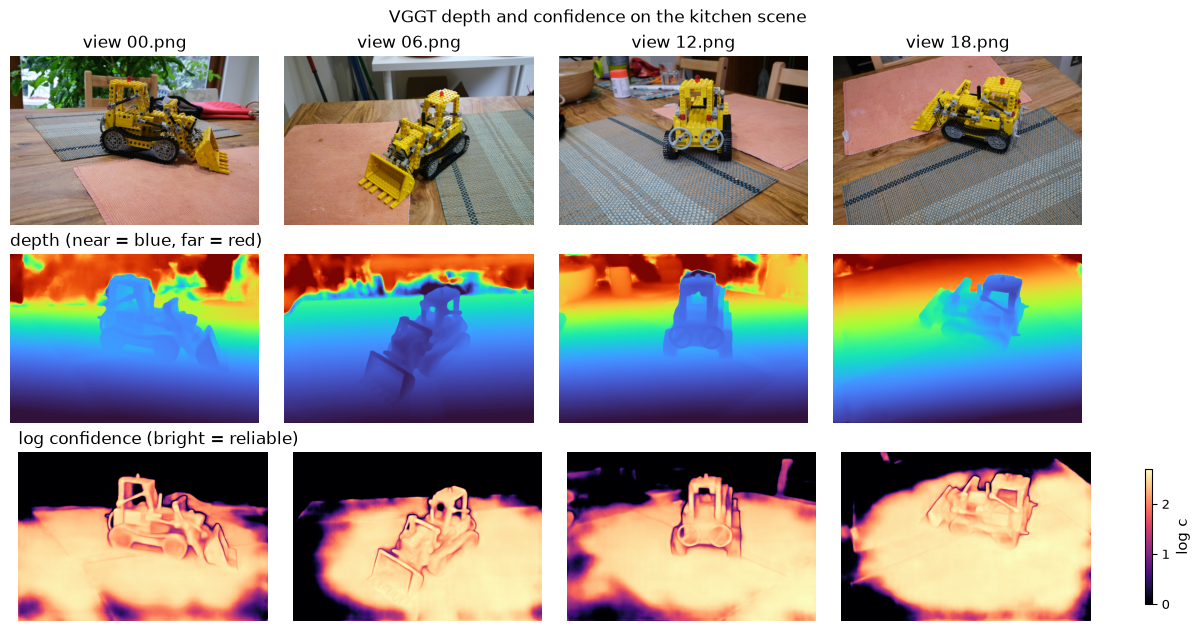

In [7]:
# --- Visualise depth and confidence for four views ---
# Depth is coloured per view with robust percentiles; confidence is shown on a log scale.
views = [0, 6, 12, 18]
fig, axes = plt.subplots(3, len(views), figsize=(12, 6.2))
for c, i in enumerate(views):
    axes[0, c].imshow(rec.images[i])
    axes[0, c].set_title(f"view {scene.names[i]}")
    axes[1, c].imshow(viz.colorize_depth(rec.depth[i], cmap="turbo"))
    im = axes[2, c].imshow(np.log(rec.conf[i]), cmap="magma")
for ax in axes.ravel():
    ax.axis("off")
axes[1, 0].set_title("depth (near = blue, far = red)", loc="left")
axes[2, 0].set_title("log confidence (bright = reliable)", loc="left")
fig.colorbar(im, ax=axes[2, :].tolist(), shrink=0.8, label="log c")
fig.suptitle("VGGT depth and confidence on the kitchen scene")
viz.savefig(fig, PROJECT, "kitchen_depth_conf")
plt.show()

## 8. Two routes to 3D points
VGGT can give a 3D point for every pixel in two ways:

1. **Depth + camera** (unprojection): $X_w = R^\top\big(z\,K^{-1}[u, v, 1]^\top - \mathbf t\big)$;
2. **Point-map head**: $X_w$ predicted directly by the point head.

The paper reports that route 1 is usually more accurate: the camera and depth heads each solve
an easier sub-problem. The two routes are trained separately, so their disagreement is a
built-in sanity check. We measure it per pixel, relative to the scene size, and bin it by
the depth confidence. The confidence $c = 1 + e^{x}$ saturates at exactly 1 for a sizeable
share of pixels, so the deciles are formed by **rank** (ties are split evenly) rather than by
confidence value.

In [8]:
# --- Compare unprojected depth with the point-map head, binned by confidence ---
# Both are in VGGT's world frame (camera 0), so they can be compared directly per pixel.
from cvlab.pointcloud import depth_to_points

ext = ff3d.trajectory_extent(C)
diffs, confs = [], []
for i in range(len(rec)):
    P_cam, _ = depth_to_points(rec.depth[i], rec.K[i], min_depth=-np.inf)  # every pixel
    T_wc = np.linalg.inv(rec.T_cw[i])
    X_unproj = P_cam @ T_wc[:3, :3].T + T_wc[:3, 3]
    X_head = rec.world_points[i].reshape(-1, 3)
    diffs.append(np.linalg.norm(X_unproj - X_head, axis=1) / ext)  # relative to scene size
    confs.append(rec.conf[i].reshape(-1))
diffs, confs = np.concatenate(diffs), np.concatenate(confs)
order = np.argsort(confs, kind="stable")  # rank of every pixel by confidence
bin_id = np.empty(len(confs), dtype=int)
bin_id[order] = np.arange(len(confs)) * 10 // len(confs)  # rank-based deciles 0..9
print(f"{100 * np.mean(confs == confs.min()):.1f} % of the pixels have the minimum confidence "
      f"{confs.min():.3f}")
consistency = pd.DataFrame({
    "confidence decile": np.arange(1, 11),
    "median |X_unproj - X_head| (% of extent)": [100 * np.median(diffs[bin_id == b]) for b in range(10)],
})
print(f"overall median disagreement: {100 * np.median(diffs):.2f} % of the camera-trajectory diameter")
consistency

19.0 % of the pixels have the minimum confidence 1.000
overall median disagreement: 0.23 % of the camera-trajectory diameter


,confidence decile,median |X_unproj - X_head| (% of extent)
0,1,3.665
1,2,4.703
2,3,0.282
3,4,0.229
4,5,0.239
5,6,0.250
6,7,0.203
7,8,0.171
8,9,0.155
9,10,0.096


## 9. Confidence filtering and `.ply` export
We keep the pixels above the 50th percentile of depth confidence, unproject them with the
predicted cameras, merge the 25 views, and voxel-downsample (a voxel of 0.5 % of the scene
size) to remove the heavy redundancy between overlapping views. The `.ply` goes to `outputs/`
(gitignored) and opens in MeshLab, CloudCompare or Open3D.

In [9]:
# --- Build a confidence-filtered, voxel-downsampled point cloud and export it ---
from cvlab.pointcloud import voxel_downsample, write_ply

pts, cols = ff3d.recon_points(rec, conf_quantile=0.5, stride=1)
pts_ds, cols_ds = voxel_downsample(pts, voxel=0.005 * ext, colors=cols)
ply = write_ply(outputs_dir(PROJECT, create=True) / "kitchen_vggt.ply", pts_ds, cols_ds)
print(f"{len(rec) * rec.proc_hw[0] * rec.proc_hw[1]:,} pixels -> {len(pts):,} confident points "
      f"-> {len(pts_ds):,} after voxel downsampling")
print("wrote", ff3d.rel(ply))

4,532,500 pixels -> 2,266,250 confident points -> 30,904 after voxel downsampling
wrote outputs/10_feedforward_3d/kitchen_vggt.ply


## 10. Sanity check against COLMAP
COLMAP's model and VGGT's live in different gauges (world frame + scale). We align VGGT's
camera centres to COLMAP's with a Sim(3) (Umeyama) fit and report pairwise pose accuracy
(AUC, gauge-free) and the absolute errors after alignment. Notebook 02 explains these metrics
in detail and runs them for all methods and scenes.

In [10]:
# --- Evaluate the VGGT cameras against the COLMAP reference (24 registered images) ---
metrics = ff3d.evaluate_poses(rec.T_cw, scene.ref_T_cw)
al = ff3d.sim3_align(rec.T_cw[ok], scene.ref_T_cw[ok])
print({k: round(v, 3) if isinstance(v, float) else v for k, v in metrics.items()})

{'n_eval': 24, 'n_total': 25, 'auc@5': 0.941, 'auc@10': 0.971, 'auc@15': 0.98, 'auc@30': 0.99, 'rra@5': 1.0, 'rta@5': 1.0, 'rel_rot_med_deg': 0.539, 'rel_trans_med_deg': 0.499, 'abs_rot_med_deg': 0.507, 'ate_pct': 0.588, 'sim3_scale': 4.312}


## Results
The figures below are saved to `assets/10_feedforward_3d/` for the README. First, the merged
point cloud with all 25 predicted cameras, rotated so that the average camera "up" vector
points up (hand-held cameras are mostly upright).

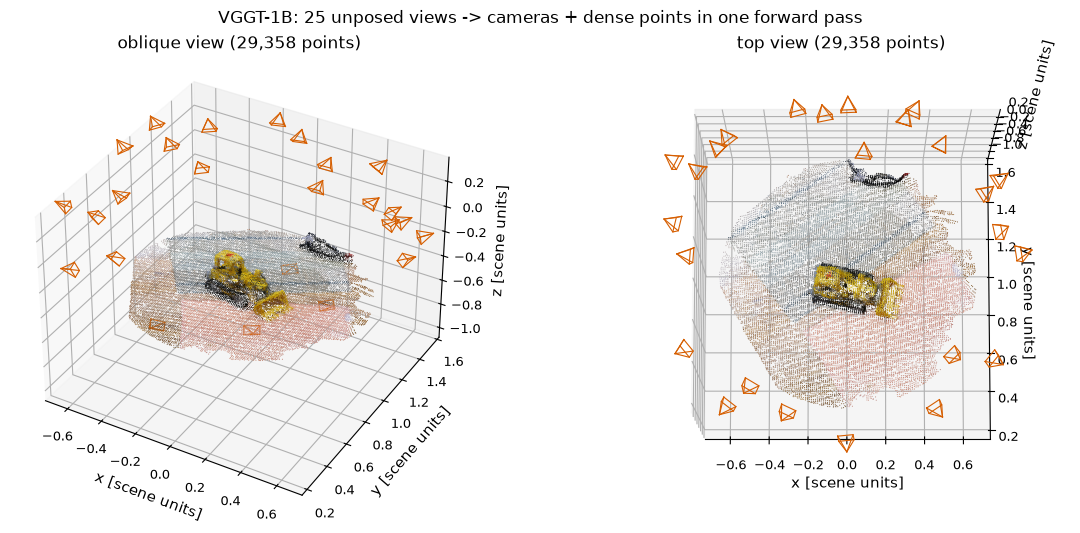

In [11]:
# --- 3D render: point cloud + predicted camera frustums (and the README thumbnail) ---
# upright_rotation() maps the mean camera up-vector (-y of OpenCV cameras) to +z.
R_up = ff3d.upright_rotation(rec.T_cw)
P_up = ff3d.sim3_apply(pts_ds, 1.0, R_up, np.zeros(3))
T_up = ff3d.sim3_apply_poses(rec.T_cw, 1.0, R_up, np.zeros(3))
P_core, C_core = ff3d.crop_to_core(P_up, cols_ds, quantile=0.95)  # drop far background
fig = plt.figure(figsize=(12, 5.2))
for k, (elev, azim) in enumerate([(35, -60), (80, -90)]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ff3d.plot_scene(ax, P_core, C_core, T_up, rec.K[0], rec.proc_hw, frustum_scale=0.04 * ext,
                    elev=elev, azim=azim,
                    title=["oblique view", "top view"][k] + f" ({len(P_core):,} points)")
fig.suptitle("VGGT-1B: 25 unposed views -> cameras + dense points in one forward pass")
viz.savefig(fig, PROJECT, "kitchen_vggt_pointcloud")
plt.show()

fig = plt.figure(figsize=(4.0, 3.3))
ax = fig.add_subplot(projection="3d")
ff3d.plot_scene(ax, P_core, C_core, T_up, rec.K[0], rec.proc_hw, frustum_scale=0.04 * ext,
                elev=35, azim=-60, max_points=20000)
ax.set_axis_off()
viz.savefig(fig, PROJECT, "thumb")
plt.close(fig)

Next, the camera centres of VGGT after the Sim(3) alignment, next to the COLMAP reference
(top view in the upright frame of the COLMAP model; the photos are an unordered collection, so
grey segments link each camera to its own reference instead of drawing a path), and the
depth/point-map consistency.

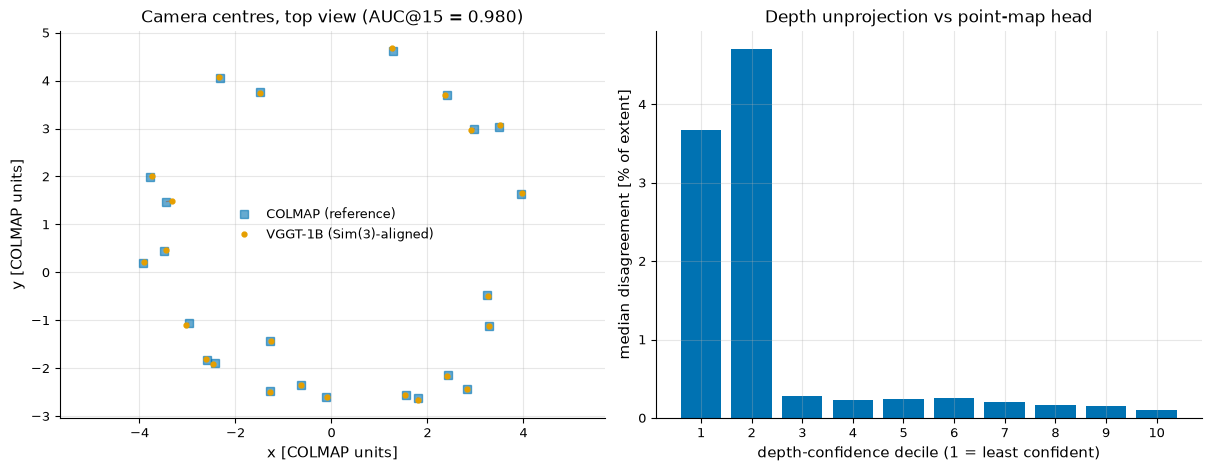

In [12]:
# --- Cameras vs COLMAP (after Sim(3) alignment) and depth/point-map consistency ---
R_ref_up = ff3d.upright_rotation(scene.ref_T_cw[ok])
C_ref = ff3d.camera_centers(scene.ref_T_cw[ok]) @ R_ref_up.T
C_vggt = al["T_wc_aligned"][:, :3, 3] @ R_ref_up.T
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ff3d.plot_cameras_topdown(axes[0], {"COLMAP (reference)": C_ref, "VGGT-1B (Sim(3)-aligned)": C_vggt},
                          dims=(0, 1), units="COLMAP units", connect=False,
                          title=f"Camera centres, top view (AUC@15 = {metrics['auc@15']:.3f})")
axes[1].bar(consistency["confidence decile"],
            consistency["median |X_unproj - X_head| (% of extent)"], color=viz.color(0, unit=True))
axes[1].set_xlabel("depth-confidence decile (1 = least confident)")
axes[1].set_ylabel("median disagreement [% of extent]")
axes[1].set_title("Depth unprojection vs point-map head")
axes[1].set_xticks(range(1, 11))
viz.savefig(fig, PROJECT, "kitchen_cameras_vs_colmap")
plt.show()

Summary of the measured numbers for this run (RTX 5060 Laptop GPU, 8 GB).

In [13]:
# --- Summary table of this notebook's measurements ---
summary = pd.DataFrame([{
    "views": len(rec), "network input (px)": f"{rec.proc_hw[1]}x{rec.proc_hw[0]}",
    "load time (s)": load_s, "forward (s)": rec.runtime_s, "peak VRAM (MiB)": rec.peak_vram_mb,
    "weights VRAM (MiB)": rec.weights_vram_mb, "FoV VGGT (deg)": fov_vggt.mean(),
    "FoV COLMAP (deg)": fov_colmap, "AUC@5": metrics["auc@5"], "AUC@15": metrics["auc@15"],
    "AUC@30": metrics["auc@30"], "median rot. err (deg)": metrics["abs_rot_med_deg"],
    "ATE (% extent)": metrics["ate_pct"], "points in .ply": len(pts_ds),
}]).T.rename(columns={0: "VGGT-1B on kitchen"})
summary

,VGGT-1B on kitchen
views,25
network input (px),518x350
load time (s),14.795
forward (s),6.666
peak VRAM (MiB),5275.729
weights VRAM (MiB),2807.844
FoV VGGT (deg),52.118
FoV COLMAP (deg),51.441
AUC@5,0.941
AUC@15,0.98


**Takeaways**

- One forward pass of VGGT-1B turns 25 unposed photos into cameras, intrinsics, depth and a
  dense point cloud in a few seconds on an 8 GB laptop GPU, once the backbone is stored in bf16
  (see the table for the measured time and memory). The weights alone take about 2.7 GiB; the
  rest of the peak is activations, which grow with the number of frames (notebook 03).
- The predicted cameras agree with a COLMAP reconstruction of the same images to within a few
  degrees. COLMAP is not ground truth either: it failed to register one of the 25 views, which
  VGGT still placed.
- The field of view is predicted per image with no EXIF. It is within about a degree of
  COLMAP's bundle-adjusted value here (see the table); any error enters directly into the 3D
  geometry.
- Confidence matters. The two routes to 3D points disagree mostly at low confidence, so
  thresholding the confidence is the cheapest way to clean the cloud.
- What you do *not* get is metric scale, or any guarantee that photometric consistency holds.
  VGGT's output is a strong initialisation; bundle adjustment (or a known trajectory, see
  notebook 03) is still needed for survey-grade geometry.

## Exercises
Solutions: `projects/10_feedforward_3d/solutions/solutions_01.py`.

**Exercise 1 - precision.** Load a second runner with `precision="bf16"` (every head in bf16
too) and compare its camera rotations with the mixed-precision ones: report the median and the
maximum per-camera rotation difference in degrees and the peak VRAM of both. (Free the first
runner with `del runner; torch.cuda.empty_cache()` first.)

In [14]:
# --- Exercise 1: all-bf16 vs mixed precision ---
# TODO: build ff3d.VGGTRunner(precision="bf16"), predict on scene.image_paths and compare
#       rec.T_cw rotations with cvlab.geometry.rotation_error_deg.

**Exercise 2 - the reference frame is the first image.** VGGT uses the first image as the
world frame (it gets a different camera token). Move image `12.png` to the front of the list,
run the model again and compare the AUC@15 against COLMAP with the original ordering. Are the
relative poses invariant to the choice of reference view?

In [15]:
# --- Exercise 2: change the reference view ---
# TODO: reorder scene.image_paths (and scene.ref_T_cw!) so that index 12 comes first,
#       predict, and evaluate with ff3d.evaluate_poses.

**Exercise 3 - a single image.** Run VGGT on `00.png` alone. How does its depth map compare
with the multi-view depth of the same view (after a median scale alignment), and how does the
single-view FoV estimate compare with COLMAP's?

In [16]:
# --- Exercise 3: single-view prediction ---
# TODO: runner.predict(scene.image_paths[:1]); compare depth with rec.depth[0] using
#       cvlab.metrics.align_depth_scale + cvlab.metrics.depth_metrics.